# Part 1 · Data analysis
Case deliverable: *general recommendation to optimise inventory management, based on data analysis* (incl. analysis of stock articles, lead time, …).

Structure: **1** data-quality audit → **2** where the capital sits → **3** stock-article health (recency) → **4** lead time → **5** demand patterns → **6** findings.
Values are in the dataset's anonymised currency units at current purchase price.

In [1]:
import sys, warnings; sys.path[:0] = ['..', '../..']; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from shared.prep import load_transactions, article_master, daily_inventory, period_demand, sbc_class, END
from src.analysis import quality_audit, entry_type_table, stock_value, recency_buckets
pd.set_option('display.float_format', '{:,.2f}'.format); pd.set_option('display.width', 200)
BLUE, ORANGE, NAVY, GREY = '#2a78d6', '#d9541e', '#13294b', '#a3a9b1'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e2da', 'axes.edgecolor': '#b5b4ad', 'font.size': 10, 'axes.titleweight': 'bold'})
FIG = '../outputs/figures'; save = lambda n: plt.savefig(f'{FIG}/{n}.png', bbox_inches='tight')
tx = load_transactions(); art = article_master(tx)
print(f'{len(tx):,} transactions · {len(art):,} articles · {art.inv_article.sum():,} inventory articles (safety stock > 0)')

2,694,849 transactions · 58,764 articles · 1,751 inventory articles (safety stock > 0)


## 1 · Data-quality audit

In [2]:
quality_audit(tx)

,Check,Result
0,Rows / articles,"2,694,849 / 58,764"
1,Period,21.01.2007 – 21.01.2022
2,Missing values,0
3,inventory_level = stock BEFORE the movement,99.9941% of rows
4,Rows inconsistent with cumulative movements,160
5,Max reported inventory_level,"1,122,648,018"
6,Quantities = integer × anonymisation factor,100.0%
7,Master-data fields varying within an article,0
8,Negative stock rows (back-orders),3.7%


In [3]:
entry_type_table(tx)

,rows,median,share_positive
entry_type,,,
0 Procurement,133443,11.11,0.72
1 Sale,432731,-4.44,0.03
2 In adjustment,18615,13.33,0.98
3 Out adjustment,26598,-7.78,0.00
4 Internal,115275,1.11,0.53
5 Usage for production,1748717,-8.89,0.00
6 In from production,219470,3.33,1.00


**Findings that shape every later step**
- `inventory_level` is the stock **before** each movement (documentation says after) → stock is rebuilt as opening level + cumulative movements.
- ~160 rows are inconsistent with the movement history (one shows 1.1 bn units) → the rebuilt level removes them.
- Every quantity is an integer multiple of 1.1107 (anonymisation); `safety_stock` and `moq` are scaled and rounded the same way → ratios between quantity fields are valid.
- Master data (`safety_stock`, `lead_time`, `moq`, price, vendor) is a single **snapshot** per article → history is valued at today's price.
- Sales carry ~3% positive rows (returns), procurement ~28% negative rows (returns to vendor) → demand is measured **net**.

## 2 · Where the capital sits

In [4]:
price = art.last_direct_cost
val = 0; val_inv = 0; last12 = pd.Series(dtype=float)
S12 = END - pd.DateOffset(years=1) + pd.Timedelta(days=1)
for ch in np.array_split(art.index.values, 30):
    e = daily_inventory(tx, ch)
    v = stock_value(e, price); val = val + v
    inv_cols = [a for a in e.columns if art.at[a, 'inv_article']]
    val_inv = val_inv + stock_value(e[inv_cols], price)
    last12 = pd.concat([last12, e.loc[S12:].fillna(0).mean() * price.reindex(e.columns)])
use = tx[tx.is_demand].assign(v=lambda d: d.demand * d.article_nr.map(price))
use_inv = use[use.article_nr.isin(art.index[art.inv_article])]
yr = pd.DataFrame({'stock_all': val.groupby(val.index.year).mean(), 'stock_inventory_articles': val_inv.groupby(val_inv.index.year).mean(),
                   'usage_inventory_articles': use_inv.groupby(use_inv.date.dt.year).v.sum()}).loc[2015:2021]
yr['stock_to_usage_%'] = 100 * yr.stock_inventory_articles / yr.usage_inventory_articles
yr['inventory_articles_share_%'] = 100 * yr.stock_inventory_articles / yr.stock_all
yr

,stock_all,stock_inventory_articles,usage_inventory_articles,stock_to_usage_%,inventory_articles_share_%
2015,"6,440,810.78","2,076,446.44","5,675,903.12",36.58,32.24
2016,"5,186,770.85","1,754,692.31","6,700,994.56",26.19,33.83
2017,"5,995,673.79","2,408,173.81","8,418,350.21",28.61,40.17
2018,"7,363,958.21","3,517,650.53","9,898,422.26",35.54,47.77
2019,"6,952,991.84","3,649,753.42","12,613,485.41",28.94,52.49
2020,"6,940,085.13","4,112,174.92","12,224,929.78",33.64,59.25
2021,"7,816,989.37","4,884,726.49","13,088,134.55",37.32,62.49


Average stock value, last 12 months: 7,874,573
  in inventory articles (safety stock > 0): 4,925,240 (63%)
  in articles WITHOUT a reorder point:      2,949,333 (37%)


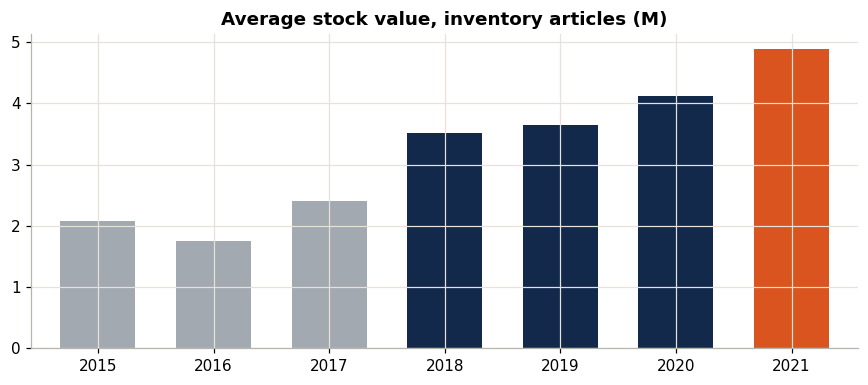

In [5]:
tot = last12.sum(); ss = art.inv_article.reindex(last12.index)
print(f'Average stock value, last 12 months: {tot:,.0f}')
print(f'  in inventory articles (safety stock > 0): {last12[ss].sum():,.0f} ({last12[ss].sum()/tot:.0%})')
print(f'  in articles WITHOUT a reorder point:      {last12[~ss].sum():,.0f} ({last12[~ss].sum()/tot:.0%})')
fig, ax = plt.subplots(figsize=(8, 3.6))
(yr.stock_inventory_articles / 1e6).plot.bar(ax=ax, color=[GREY]*3 + [NAVY]*3 + [ORANGE], width=.65)
ax.set_title('Average stock value, inventory articles (M)'); ax.set_xlabel(''); plt.xticks(rotation=0)
plt.tight_layout(); save('p1_lockup_trend'); plt.show()

**Read:** inventory articles are 3% of articles but hold ~62% of stock value; their stock grew **+39% (2018→2021)**, faster than usage
(stock-to-usage 29% → 37%). And **37% of stock value sits in articles without a reorder point**: stock that no replenishment rule manages.

## 3 · Stock-article health: when was an article last sold or used?

{'< 1 yr': 1433, '1–2 yrs': 52, '2–3 yrs': 14, '3–5 yrs': 11, '> 5 yrs / never': 241}
Stock value in articles idle > 1 year (all articles): 935,959  ·  idle ≥ 3 years / never: 421,457


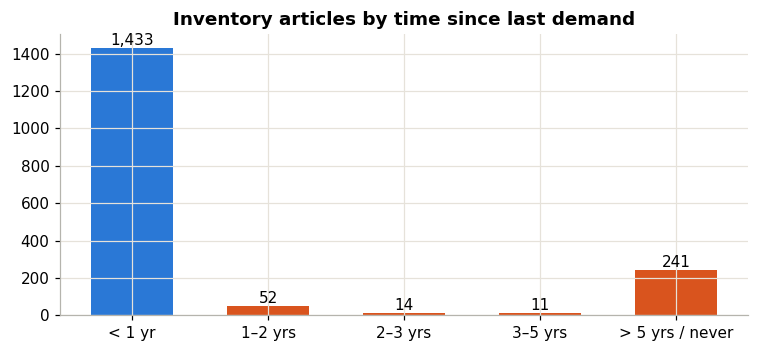

In [6]:
dm = tx[tx.is_demand & (tx.demand > 0)].groupby('article_nr').date.max()
months = ((END - dm).dt.days / 30.44).reindex(art.index)
inv = art.inv_article
rb = recency_buckets(months[inv]).value_counts().sort_index()
rv = last12.reindex(art.index).fillna(0)
idle = (months > 12) | months.isna()
print(rb.to_dict())
print(f'Stock value in articles idle > 1 year (all articles): {rv[idle].sum():,.0f}  ·  idle ≥ 3 years / never: {rv[(months > 36) | months.isna()].sum():,.0f}')
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.bar(rb.index.astype(str), rb.values, color=[BLUE] + [ORANGE]*4, width=.6)
for i, v in enumerate(rb.values): ax.text(i, v, f'{v:,}', ha='center', va='bottom')
ax.set_title('Inventory articles by time since last demand'); plt.tight_layout(); save('p1_recency'); plt.show()

**Read:** 318 inventory articles (18%) still carry a reorder point although they have had no demand for over a year. Across all articles about
**0.94M** of stock has been idle for more than a year, 0.42M of it in articles with no demand for 3+ years → write-down / sell-off candidates.

## 4 · Lead time

Lead time maintained: 98% of inventory articles vs 21% of other articles
Most common values (inventory articles): {30: 553, 15: 381, 10: 226, 45: 197, 5: 157, 60: 82}


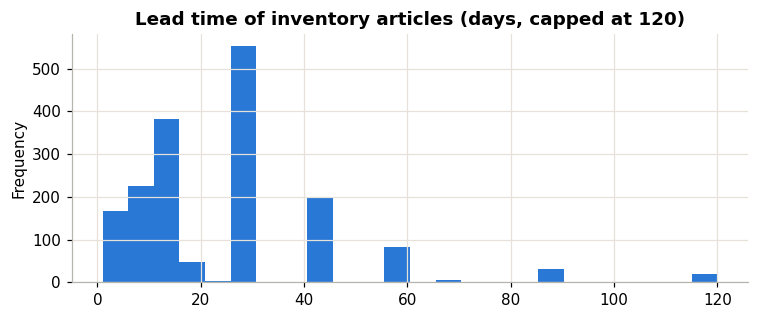

In [7]:
lt = art.lead_time
print(f'Lead time maintained: {(lt[inv] > 0).mean():.0%} of inventory articles vs {(lt[~inv] > 0).mean():.0%} of other articles')
print('Most common values (inventory articles):', lt[inv].value_counts().head(6).to_dict())
fig, ax = plt.subplots(figsize=(7, 3.0))
lt[inv & (lt > 0)].clip(upper=120).plot.hist(bins=24, ax=ax, color=BLUE)
ax.set_title('Lead time of inventory articles (days, capped at 120)'); plt.tight_layout(); save('p1_lead_time'); plt.show()

**Read:** lead times are maintained for almost all inventory articles but cluster on round planning values (15 / 30 days): they are
manual settings, not measurements. The data has no order dates, so lead-time *variability* cannot be measured. A data gap to close.

## 5 · Demand patterns of inventory articles

In [8]:
S36 = END - pd.DateOffset(years=3)
mon = period_demand(tx, art.index[inv], S36, days=30)
cls = sbc_class(mon)
v12 = last12.reindex(cls.index).fillna(0)
t = cls.assign(stock=v12).groupby('demand_class').agg(articles=('stock', 'size'), stock_value=('stock', 'sum'))
t['stock_%'] = 100 * t.stock_value / t.stock_value.sum(); t.sort_values('articles', ascending=False)

,articles,stock_value,stock_%
demand_class,,,
Lumpy,603,"1,126,533.92",22.87
Erratic,373,"1,465,248.67",29.75
No demand,252,"143,184.38",2.91
Intermittent,209,"335,244.32",6.81
Smooth,166,"1,639,656.52",33.29
Sporadic,148,"215,372.04",4.37


**Read:** only ~10% of inventory articles have smooth demand; ~75% are erratic, lumpy, intermittent or sporadic (the case's *searched demand*).
Rare large orders dominate volume → one textbook safety-stock formula does not fit all articles (Part 3).

## 6 · Findings → recommendations
| Finding | Recommendation |
|---|---|
| Stock in inventory articles +39% since 2018, faster than usage | Reduce through demand-driven levels (Part 3) |
| 37% of stock value in articles without a reorder point | Decide per class which articles belong on stock (Part 2) |
| ~0.94M idle > 1 year; 318 inventory articles idle | Clean-up: de-list, run down, sell off |
| Lead times manual, no order dates | Record order & receipt dates; measure real lead times |
| ~75% irregular demand, rare large orders | Pattern-specific methods; plan large orders via orders, not stock |